# Solutions to exercises

## 1. Adiabatic accretion

We can evaluate the mass accretion rate at the sonic point $r_s=GM/2c_s^2$, where $c_s$ refers to the sound speed at the sonic point. Then
$$\dot M = 4\pi r_s^2\rho_s c_s = \pi {(GM)^2\rho_s\over c_s^3}.$$

To write the sound speed and density at the sonic point in terms of those at infinity, we can use the Bernoulli constant. For an adiabatic equation of state the Bernoulli constant is
$$B = {1\over 2}v^2 + {c^2\over \gamma-1} - {GM\over r},$$
where we write the sound speed at a general location as $c=\sqrt{\gamma P/\rho}$. Evaluating $B$ at the sonic point gives
$$B = {c_s^2\over 2} + {c_s^2\over \gamma-1} - {GM\over r_s} = c_s^2\left[{1\over 2} + {1\over \gamma-1} - 2\right] = c_s^2 {5-3\gamma\over 2(\gamma-1)},$$
which must also equal $B$ at large distance where $c=c_\infty$ and $v=0$,
$$B = {c_\infty^2\over \gamma-1}.$$
Therefore
$$ c_s^2 = {2\over 5-3\gamma} c_\infty^2,$$
or
$$ {c_s^3\over c_\infty^3} = \left( {2\over 5-3\gamma} \right)^{3/2} $$
Since $c^2 = \gamma P/\rho\propto \rho^{\gamma-1}$, we have $\rho\propto c^{2/\gamma-1}$, and therefore
$${\rho_s\over \rho_\infty} = \left( {2\over 5-3\gamma} \right)^{1/(\gamma-1)}$$
$${\rho_s\over \rho_\infty}{c_\infty^3\over c_s^3} = \left( {2\over 5-3\gamma} \right)^{{1\over \gamma-1} - {3\over 2}} = \left( {2\over 5-3\gamma} \right)^{(5-3\gamma)/2(\gamma-1)}$$
which then gives the result in the question for $\dot M$.

The isothermal limit $\gamma\rightarrow 1$ is a bit tricky. [Evaluating the limit](https://www.wolframalpha.com/input?i=Limit%5B%282%2F%285-3x%29%29%5E%28%285-3x%29%2F%282%28x-1%29%29%29%2C+x-%3E1%5D)
```
Limit[(2/(5-3x))^((5-3x)/(2(x-1))), x->1]
```
gives $e^{3/2}$, in agreement with the isothermal derivation in the notes.

## 2. Thermal equilibria of a thin disk

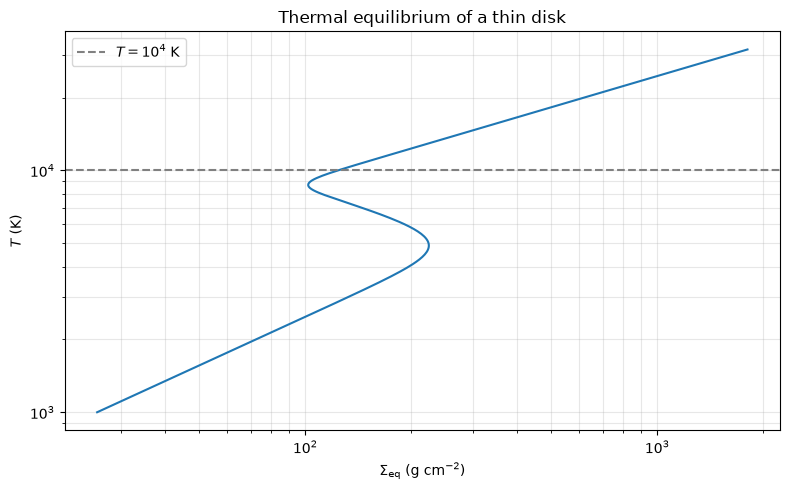

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

sigma_SB = 5.67e-5
kB = 1.38e-16
mp = 1.67e-24

# Disk parameters
alpha = 0.1
mu = 0.6
Omega = 2*np.pi / 1e5

def kappa(rho, T):
    # free-free at high T (ionized hydrogen)
    kappa1 = 6.6e22 * rho * T**(-3.5)
    # H- at low T, with a minimum from dust
    kappa2 = 2.5e-31 * rho**0.5 * T**9 + 0.1
    return 1/np.sqrt((1/kappa1**2) + (1/kappa2**2))

def f(sigma, T):
    cs = np.sqrt(kB*T / (mu*mp))
    H = cs / Omega
    rho = sigma / H

    Q_plus = alpha * cs * H * Omega**2 * sigma
    Q_minus = sigma_SB * T**4 / (kappa(rho,T) * sigma)

    return Q_plus - Q_minus

def find_sigma(T):
    return brentq(f,1,1e4,args=(T,))

# Temperature range
T = np.logspace(3, 4.5, 300)

# Calculate equilibrium column depth
sigma_eq = np.array([find_sigma(t) for t in T])

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(sigma_eq,T)
ax.axhline(1e4, color="gray", linestyle="--", label=r"$T=10^4$ K")

ax.set_ylabel(r"$T$ (K)")
ax.set_xlabel(r"$\Sigma_{\rm eq}$ (g cm$^{-2}$)")
ax.set_title("Thermal equilibrium of a thin disk")
ax.legend()
ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

The region above the $S$-shaped curve has $Q_->Q_+$. So if you start above the curve, then the temperature will drop. If you start below the curve, where $Q_+>Q_-$, temperature will increase. This means that the part of the curve that goes backwards ($dT/d\Sigma<0$) is unstable. A small perturbation to the temperature means you will either go up to the stable hot branch or down to the stable cold branch. This curve is the basis for time-dependent behavior in accretion disks, e.g. Hameury (2020) [A review of the disc instability model for dwarf novae, soft X-ray transients and related objects](https://ui.adsabs.harvard.edu/abs/2020AdSpR..66.1004H/abstract).

## 3. Magnetized accretion

(a) For accretion to be magnetically-controlled, we need $r_M>R_\star$, where $R_\star$ is the radius of the star. Dividing the expression for $r_M$ from the notes by $R_\star$
$${r_M\over R_\star} = 5 \left({R_\star\over 10^8\ \mathrm{cm}}\right)^{-1} \mu_{30}^{4/7} \dot M_{16}^{-2/7} \left({M\over M_\odot}\right)^{-1/7}$$
$$= 5 \left({R_\star\over 10^8\ \mathrm{cm}}\right)^{5/7} \left({B_\star\over 10^6\ \mathrm{G}}\right)^{4/7} \dot M_{16}^{-2/7} \left({M\over M_\odot}\right)^{-1/7}.$$
Or if we want $r_M = R_\star$, then
$$ B_\star = 6.0\times 10^4\ \mathrm{G}\ \left({R_\star\over 10^8\ \mathrm{cm}}\right)^{-5/4}  \dot M_{16}^{1/2} \left({M\over M_\odot}\right)^{1/4}.$$


In [22]:
def Bcrit(R, Mdot, M):
    return 6e4 * (R/1e8)**(-5/4) * (Mdot/1e16)**0.5 * M**0.25

msun_per_yr = 1.989e33 / 3.15e7
mearth_per_yr = 5.972e27 / 3.15e7

names = ('NS', 'WD', 'planet', 'young Sun')
Mvec = (1.4, 0.6, 1e-3, 1.0)
Mdot = (1e-8 * msun_per_yr, 1e-10 * msun_per_yr, 1e-3 * mearth_per_yr, 1e-8 * msun_per_yr)
R = (1e6, 1e9, 1e10, 1e11)

for i in range(4):
    print("%s: Mdot=%lg B=%lg\n" % (names[i],Mdot[i],Bcrit(R[i],Mdot[i],Mvec[i]),))

NS: Mdot=6.31429e+17 B=1.64001e+08

WD: Mdot=6.31429e+15 B=2359.67

planet: Mdot=1.89587e+17 B=146.912

young Sun: Mdot=6.31429e+17 B=84.7839



These are very reachable magnetic fields in each case. Accreting neutron stars have fields in the range $10^8-10^{12}\ \mathrm{G}$, so magnetic accretion is common. For a young planet or star, kG fields are possible, and accreting white dwarfs are known with fields as high as $10^9\ \mathrm{G}$. 

(b) The orbital period is given by $\Omega^2 =(2\pi/P_\mathrm{orb})^2 = GM_\star/r_M^3$.

In [23]:
def rM(B,Mdot,M,R):
    mu = B * R**3
    rM = 5e8 * (1e-30*mu)**(4/7) * (1e-16*Mdot)**(-2/7) * M**(-1/7)
    return rM
    
def Porb(B,Mdot,M,R):
    Ggrav = 6.67e-8
    Porb = 2*np.pi*(rM(B,Mdot,M,R)**3/(Ggrav*1.989e33*M))**0.5
    return Porb/3600

B = (1e12, 1e7, 1e3, 1e3)

for i in range(4):
    print("%s: Mdot=%lg, B=%lg, rM=%lg, P=%lg h\n" % 
          (names[i],Mdot[i],B[i],rM(B[i],Mdot[i],M[i],R[i]),Porb(B[i],Mdot[i],M[i],R[i]),))

NS: Mdot=6.31429e+17, B=1e+12, rM=1.45786e+08, P=0.000225428 h

WD: Mdot=6.31429e+15, B=1e+07, rM=1.18421e+11, P=7.97191 h

planet: Mdot=1.89587e+17, B=1000, rM=2.99736e+10, P=24.866 h

young Sun: Mdot=6.31429e+17, B=1000, rM=4.10358e+11, P=39.8329 h



X-ray pulsars are accreting neutron stars in binaries with magnetically-channelled accretion and periods of order seconds, they are in this equilibrium. The white dwarf answer is interesting because the magnetospheric radius can become comparable to the size of the binary orbit, so that mass transfer from a companion is magnetically controlled all the way, with no accretion disk forming.

## 4. Two-temperature accretion

## 5. Parker's argument for a wind

(a) If there are no energy sources in the wind then the divergence of the heat flux should vanish. In spherical coordinates, this is 
$${1\over r^2}{d\over dr}\left(r^2 F\right) =0,$$
or alternatively we must have 
$$r^2F = -r^2 K {dT\over dr} \propto r^2 T^n {dT\over dr} = rT^{n+1} {d\ln T\over d\ln r} = \mathrm{constant},$$
which is indeed satisfied if we take $T\propto r^{-1/(1+n)}$.

(b) Now look at hydrostatic balance 
$${dP\over dr} = -\rho {GM\over r^2}$$
$$\Rightarrow {k_B\over \mu m_p} {d(\rho T)\over dr} =  {k_BT\over \mu m_p} \left[{d\rho\over dr} + \rho {d\ln T\over dr}\right] = - \rho {GM\over r^2}$$ 
$$\Rightarrow {d\rho\over dr} + {\rho\over r}{d\ln T\over d\ln r} = -{\mu m_p\over k_BT} \rho {GM\over r^2}$$
$$\Rightarrow {d\ln \rho\over dr} = {1\over r}{1\over 1+n} -{\mu m_p\over k_BT} {GM\over r^2}$$
$$\Rightarrow {d\ln \rho\over dr} = {1\over r}{1\over 1+n} -{\mu m_p\over k_B T_0} \left({r\over a}\right)^{1/(1+n)} {GM\over r^2}$$
Parker defined the parameter $\lambda = GMm_p/2k_BTa$ where the factor of 2 is coming from $\mu=1/2$ for fully-ionized atomic hydrogen. So let's write
$$\lambda = {\mu m_p GM\over k_BT_0 a}$$ 
which gives
$${d\ln \rho\over dr} = {1\over r}{1\over 1+n} - \left({r\over a}\right)^{1/(1+n)} {\lambda a\over r^2}.$$
Integrate outwards from $a$ to radius $r$:
$$\ln\left({\rho\over\rho_0}\right) = {1\over 1+n}\ln \left({r\over a}\right) + \lambda{1+n\over n}\left[\left({r\over a}\right)^{-n/(1+n)}   - 1\right],$$
which is eq. (4) in Parker (1958). The pressure profile is then given by $P = \rho k_B T/\mu m_p$.

(c) Now look what happens at large distance. For $r\gg a$ the density is
$$\rho = \rho_0 \left({r\over a}\right)^{1/(1+n)} \exp\left(-\lambda {1+n\over n}\right)$$
so the pressure is
$$P\propto \rho T\propto \left({r\over a}\right)^{1/(1+n)} \exp\left(-\lambda {1+n\over n}\right) \left({a\over r}\right)^{1/(1+n)} = \exp\left(-\lambda {1+n\over n}\right)  $$
The pressure remains non-zero at large distance! This is Parker's argument: if we assume hydrostatic balance, there is a large unbalanced pressure at large distances that will blow out gas, forming a wind.

## 6. The solar wind

(a) The equation pointed to from the notes, obtained by combining the continuity and momentum equations, is 
$$\left(v - {c_s^2\over v}\right){dv\over dr} = {2c_s^2\over r} - {GM\over r^2}.$$
Write this as
$$vdv - c_s^2 d\ln v = 2c_s^2 {d\ln r} - {GM\over r^2}dr.$$
Integrate this from the sonic point to some other location:
$${v^2\over 2} - {c_s^2\over 2} - c_s^2 \ln \left({v\over c_s}\right) = 2 c_s^2 \ln\left({r\over r_s}\right) + {GM\over r_s} \left({r_s\over r} - 1\right)$$
$$\Rightarrow {v^2\over 2} - {c_s^2\over 2} - c_s^2 \ln \left({v\over c_s}\right) = 2 c_s^2 \ln\left({r\over r_s}\right) + 2c_s^2 \left({r_s\over r} - 1\right)$$
$$\Rightarrow {v^2\over c_s^2} - 1 - \ln \left({v\over c_s}\right)^2 = 4 \ln\left({r\over r_s}\right) + 4 \left({r_s\over r} - 1\right)$$
$$\Rightarrow {v^2\over c_s^2} - \ln \left({v\over c_s}\right)^2 = 4 \ln\left({r\over r_s}\right) + 4 \left({r_s\over r}\right) - 3,$$
which is the result we are looking for.

(b) Now apply this to the Sun.

T=500000, rs=1.60545e+12
T=1e+06, rs=8.02727e+11
T=2e+06, rs=4.01364e+11
T=4e+06, rs=2.00682e+11


/tmp/ipykernel_303730/665341175.py:11: RuntimeWarning: invalid value encountered in log
  f = M2 - np.log(M2) - 4*np.log(x) - (4/x) + 3


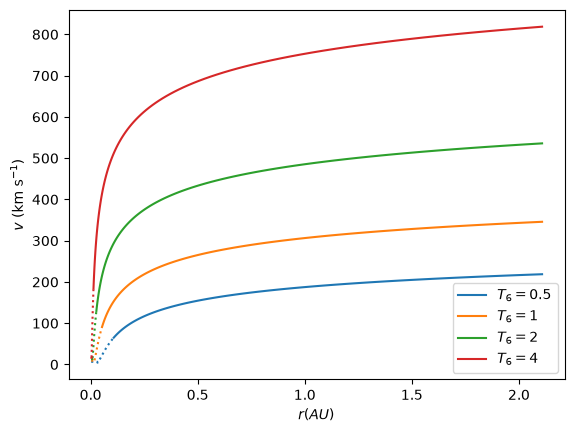

In [100]:
from scipy.optimize import root

Msun = 1.989e33
kB = 1.38e-16
mp = 1.67e-24
GM = 6.67e-8*Msun

Tvec = (0.5e6, 1e6, 2e6, 4e6)

def f(M2,x):
    f = M2 - np.log(M2) - 4*np.log(x) - (4/x) + 3
    #print(M2,x,f)
    return f
    
for j,T in enumerate(Tvec):
    cs2 = (kB*T/mp)
    rs = (GM/2/cs2)

    print("T=%lg, rs=%lg" % (T, rs))

    rvec = np.linspace(np.log10(1.01*rs),13.5,100)
    M2vec = np.zeros_like(rvec)
    for i,r in enumerate(rvec):
        x = 10**r / rs
        if i>0:
            guess = M2vec[i-1]
        else:
            guess = 1.1
        sol = root(f,guess,args=(x,))
        M2vec[i] = sol.x[0]

    plt.plot(10**rvec/1.5e13,np.sqrt(M2vec*cs2)/1e5, 'C%d' % (j,), label = r'$T_6=%lg$' % (T*1e-6,))

    rvec = np.linspace(10.6,np.log10(rs),100)
    M2vec = np.zeros_like(rvec)
    for i,r in enumerate(rvec):
        x = 10**r / rs
        if i>0:
            guess = M2vec[i-1]
        else:
            guess = 0.01
        sol = root(f,guess,args=(x,))
        M2vec[i] = sol.x[0]

    plt.plot(10**rvec/1.5e13,np.sqrt(M2vec*cs2)/1e5, 'C%d:' % (j,))

#plt.yscale('log')
#plt.xscale('log')
plt.ylabel(r'$v\ (\mathrm{km\ s^{-1}})$')
plt.xlabel(r'$r (AU)$')
plt.legend()
plt.show()

The speed at Earth is hundreds of km/s, larger for larger temperature. The sonic point is $\lesssim 0.1\ \mathrm{AU}$, and gets closer to the Sun for larger values of temperature.